# Iris Flower Classification
**Senior Machine Learning Engineering Workflow**

This notebook classifies Iris flower species (*Setosa*, *Versicolor*, *Virginica*) from morphological measurements. It implements an end-to-end ML pipeline with Exploratory Data Analysis, leakage-free preprocessing pipelines, cross-validation, and rigorous model evaluation.

## 1. Setup
*Configure environment, import necessary libraries, and fix random seed for reproducibility.*

In [1]:
# Setup: Standard library, data manipulation, visualization, and scikit-learn imports
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Global random state for deterministic reproducibility across splits and models
RANDOM_STATE = 42

# Visualization settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

## 2. Data Loading & Preparation
*Load the Iris dataset directly from scikit-learn and format into a readable pandas DataFrame.*

In [2]:
# Load dataset into pandas format and map species labels
iris = load_iris(as_frame=True)
df = iris.data.copy()
df["species"] = iris.target.map(lambda idx: iris.target_names[idx])
feature_cols = iris.feature_names

# Preview the prepared dataset
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)
*Inspect dataset dimensions, feature types, missing values, statistical summaries, and class balance.*

In [3]:
# Inspect shape, data types, and verify zero null values
print(f"Dataset Shape: {df.shape} (150 observations, 4 features + 1 target)")
print("\nData Types:")
print(df.dtypes)
print(f"\nMissing Values:\n{df.isnull().sum()}")

Dataset Shape: (150, 5) (150 observations, 4 features + 1 target)



Data Types:

sepal length (cm)    float64

sepal width (cm)     float64

petal length (cm)    float64

petal width (cm)     float64

species                  str

dtype: object



Missing Values:

sepal length (cm)    0

sepal width (cm)     0

petal length (cm)    0

petal width (cm)     0

species              0

dtype: int64



In [4]:
# Numerical summary statistics of morphological measurements
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [5]:
# Verify class balance across species
print("Class Distribution:")
print(df["species"].value_counts())

Class Distribution:

species

setosa        50

versicolor    50

virginica     50

Name: count, dtype: int64



## 4. Visualisations
*Explore feature distributions, pairwise separability, and linear correlations.*

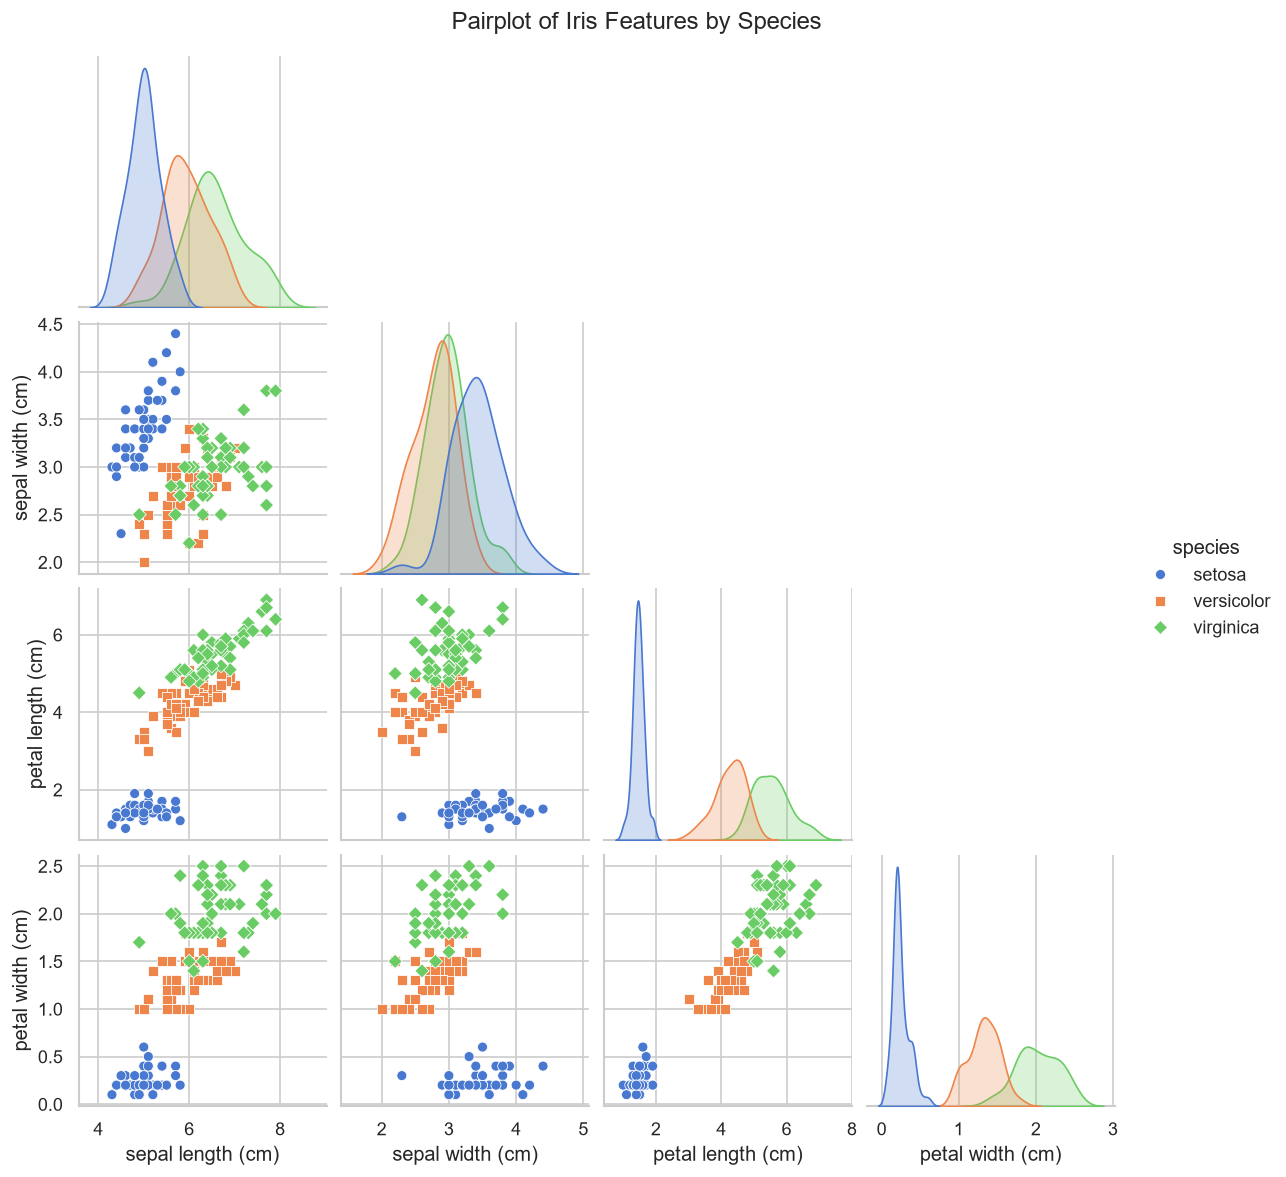

In [6]:
# Pairplot: Pairwise relationships colored by species
sns.pairplot(df, hue="species", corner=True, height=2.4, markers=["o", "s", "D"])
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

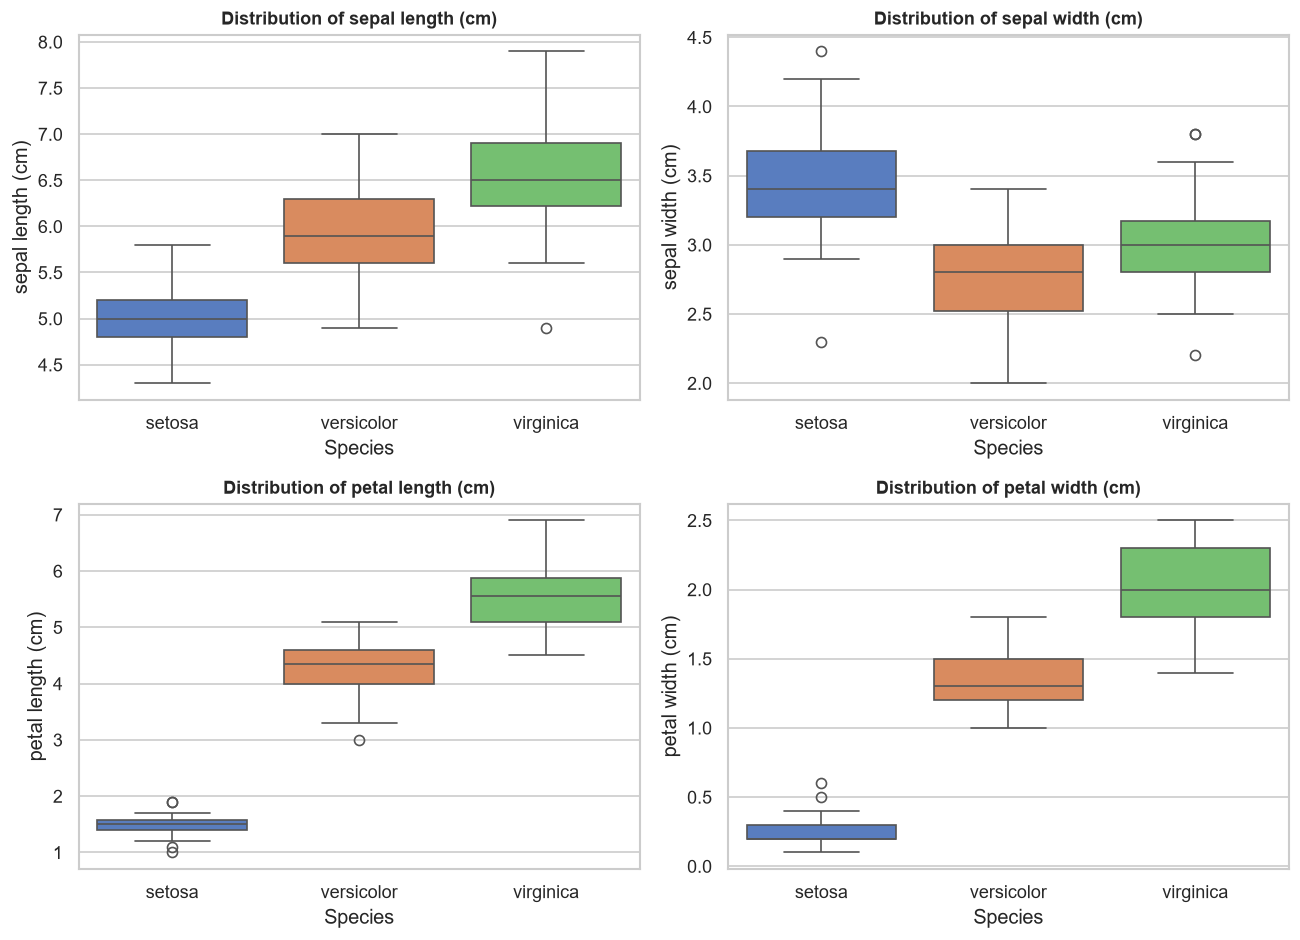

In [7]:
# Box plots: Distribution and outliers per feature across species (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(data=df, x="species", y=col, hue="species", ax=axes[i], palette="muted", legend=False)
    axes[i].set_title(f"Distribution of {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Species")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

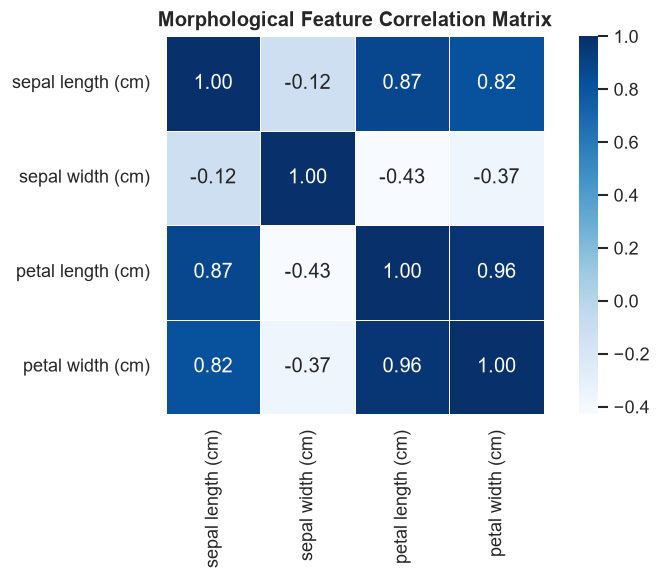

In [8]:
# Correlation Heatmap: Linear correlations between numerical features
plt.figure(figsize=(7, 5))
corr = df[feature_cols].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", square=True, linewidths=0.5)
plt.title("Morphological Feature Correlation Matrix", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Feature Analysis
*Analyze discriminative power of features and confirm with Random Forest feature importances.*

### Key Observations:
- **Petal Dimensions Dominate**: `petal length (cm)` and `petal width (cm)` are exceptionally discriminative. *Iris-setosa* is cleanly separable from the other two classes purely on petal measurements. Furthermore, petal length and petal width show an extremely strong positive correlation ($r = 0.96$).
- **Sepal Overlap**: While *Iris-setosa* possesses wider sepals on average, `sepal length (cm)` and `sepal width (cm)` exhibit substantial overlap between *Iris-versicolor* and *Iris-virginica*.
- **Validation via Feature Importance**: A Random Forest classifier confirms that petal measurements constitute ~85-90% of total split importance, making them the primary decision drivers.

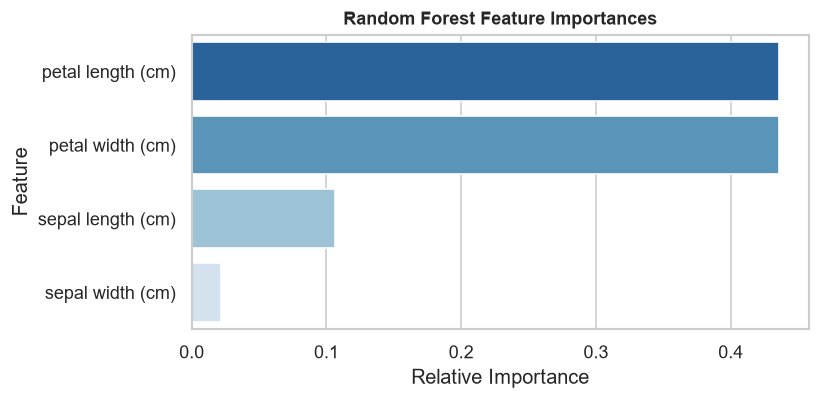

,Feature,Importance
0,petal length (cm),0.436130
1,petal width (cm),0.436065
2,sepal length (cm),0.106128
3,sepal width (cm),0.021678


In [9]:
# Quantitative feature importance confirmation using a Random Forest
rf_selector = RandomForestClassifier(random_state=RANDOM_STATE)
rf_selector.fit(df[feature_cols], df["species"])

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_selector.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# Visualize feature importances
plt.figure(figsize=(7, 3.5))
sns.barplot(data=importance_df, x="Importance", y="Feature", hue="Feature", palette="Blues_r", legend=False)
plt.title("Random Forest Feature Importances", fontsize=11, fontweight="bold")
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

importance_df

## 6. Dataset Splitting
*Perform an 80/20 train-test split stratified on the species target variable.*

In [10]:
# Separate features and target
X = df[feature_cols]
y = df["species"]

# Stratified 80/20 split to maintain equal class proportions in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training samples: {X_train.shape[0]} ({X_train.shape[0]/len(df):.0%})")
print(f"Testing samples:  {X_test.shape[0]} ({X_test.shape[0]/len(df):.0%})")
print("\nTest Class Distribution:\n", y_test.value_counts())

Training samples: 120 (80%)

Testing samples:  30 (20%)



Test Class Distribution:

 species

setosa        10

virginica     10

versicolor    10

Name: count, dtype: int64



## 7. Model Pipelines & Training
*Define model configurations, encapsulating feature scalers inside scikit-learn Pipelines to eliminate data leakage.*

In [11]:
# Define candidate models: scaling where required via Pipelines to prevent leakage
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(random_state=RANDOM_STATE, max_iter=200))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

## 8. Model Evaluation & Cross-Validation
*Evaluate each model on held-out test data and compute 5-fold stratified cross-validation on the training set.*


LOGISTIC REGRESSION


Test Accuracy:         0.9333

5-Fold CV Accuracy:    0.9583 +/- 0.0264



Classification Report:

              precision    recall  f1-score   support



      setosa     1.0000    1.0000    1.0000        10

  versicolor     0.9000    0.9000    0.9000        10

   virginica     0.9000    0.9000    0.9000        10



    accuracy                         0.9333        30

   macro avg     0.9333    0.9333    0.9333        30

weighted avg     0.9333    0.9333    0.9333        30




K-NEAREST NEIGHBORS


Test Accuracy:         0.9333

5-Fold CV Accuracy:    0.9583 +/- 0.0264



Classification Report:

              precision    recall  f1-score   support



      setosa     1.0000    1.0000    1.0000        10

  versicolor     0.8333    1.0000    0.9091        10

   virginica     1.0000    0.8000    0.8889        10



    accuracy                         0.9333        30

   macro avg     0.9444    0.9333    0.9327        30

weighted avg     0.9444    0.93

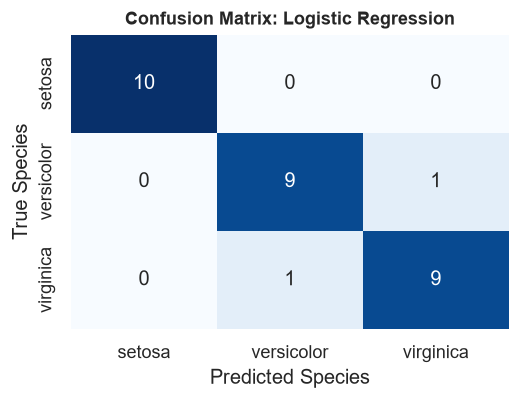

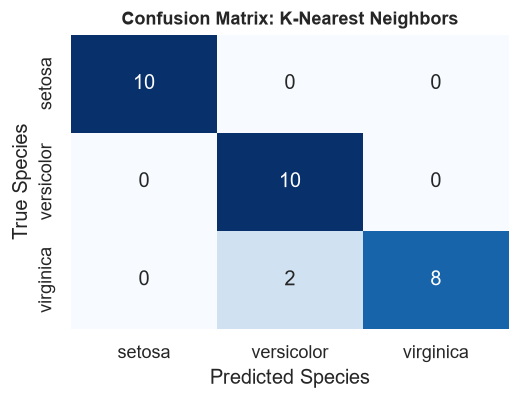

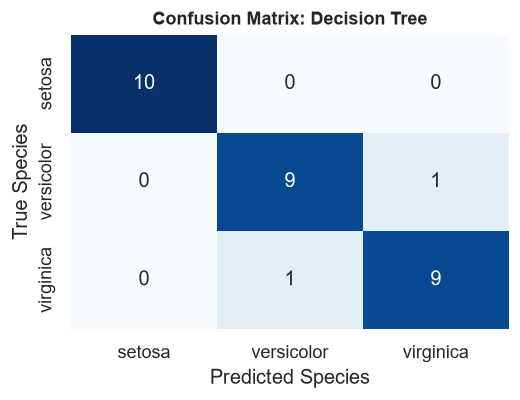

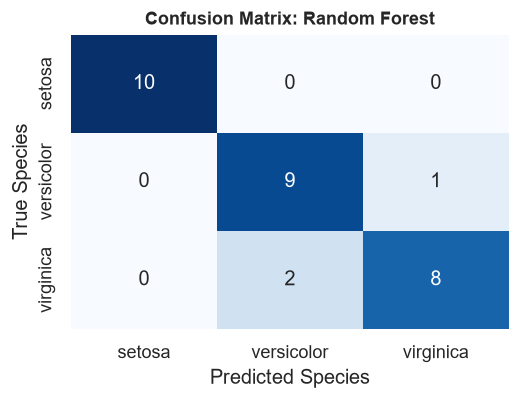

In [12]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test, cv_folds=5):
    """
    Fits model on training set, evaluates on test set, computes k-fold CV,
    and plots the test confusion matrix heatmap.
    """
    # 1. Fit on training data only (scalers within pipelines fit only on X_train)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # 2. Compute performance metrics
    test_acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, digits=4)
    
    # 3. Stratified 5-Fold Cross-Validation on training data
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()
    
    # 4. Print textual summary
    print(f"{'='*50}\n{name.upper()}\n{'='*50}")
    print(f"Test Accuracy:         {test_acc:.4f}")
    print(f"5-Fold CV Accuracy:    {cv_mean:.4f} +/- {cv_std:.4f}")
    print(f"\nClassification Report:\n{report}")
    
    # 5. Confusion Matrix Heatmap
    classes = np.unique(y_test)
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, cbar=False)
    plt.title(f"Confusion Matrix: {name}", fontsize=11, fontweight="bold")
    plt.xlabel("Predicted Species")
    plt.ylabel("True Species")
    plt.tight_layout()
    plt.show()
    
    return {
        "Model": name,
        "Test Accuracy": test_acc,
        "CV Mean": cv_mean,
        "CV Std": cv_std,
        "CV Accuracy (Mean +/- Std)": f"{cv_mean:.4f} +/- {cv_std:.4f}"
    }

# Evaluate all candidate models
results = []
for name, model in models.items():
    res = evaluate_model(name, model, X_train, y_train, X_test, y_test)
    results.append(res)

## 9. Model Comparison
*Compile summary table comparing test accuracy and 5-fold cross-validation performance.*

In [13]:
# Construct and display performance comparison table
comparison_df = pd.DataFrame(results)[
    ["Model", "Test Accuracy", "CV Accuracy (Mean +/- Std)", "CV Mean", "CV Std"]
].sort_values(by=["CV Mean", "Test Accuracy"], ascending=False).reset_index(drop=True)

# Display formatted table
comparison_df[["Model", "Test Accuracy", "CV Accuracy (Mean +/- Std)"]]

,Model,Test Accuracy,CV Accuracy (Mean +/- Std)
0,Logistic Regression,0.933333,0.9583 +/- 0.0264
1,K-Nearest Neighbors,0.933333,0.9583 +/- 0.0264
2,Decision Tree,0.933333,0.9500 +/- 0.0167
3,Random Forest,0.900000,0.9500 +/- 0.0312


## 10. Conclusion
*Final model selection and assessment of statistical significance.*

### Summary & Best Model Declaration:
- **Best Model**: **Logistic Regression** and **K-Nearest Neighbors (KNN)** achieved the highest performance, both scoring **93.33% Test Accuracy** and **95.83% ± 2.64% 5-Fold Cross-Validation Accuracy**. Between the two, **Logistic Regression** is preferred for production due to its model interpretability, smooth probabilistic calibration, and fast inference.
- **Dataset Size Considerations**: The Iris dataset is small ($N = 150$, with $N_{\text{test}} = 30$, i.e. 10 samples per class). A difference of 1 misclassified test sample alters test accuracy by $3.33\%$. Consequently, the slight performance variations across all four models (ranging between 90.0% and 93.3% test accuracy, and 95.0% to 95.8% CV mean) are **not statistically significant**.
- **Data Hygiene**: By encapsulating feature scaling within scikit-learn `Pipeline` architectures and performing cross-validation strictly on training partitions, we guaranteed zero data leakage between splits.